In [48]:
import os
import json
from collections import defaultdict

folder = '../results/tag/USR'
entities = ['Understandable', 'Maintains Context', 'Natural', 'Uses Knowledge', 'Interesting']
closests = []
farthests = []
total_results = []

def coverage(tags, entities):
    """Recall: Fraction of entities covered by tags."""
    return len(set(tags) & set(entities)) / len(entities)

def diversity(tags, entities):
    """1 - Precision: Fraction of tags not in entities."""
    if not tags:
        return 0
    return 1 - (len(set(tags) & set(entities)) / len(set(tags)))

model_files = defaultdict(list)
for fname in os.listdir(folder):
    if fname.endswith('.json') and fname.startswith('model_name='):
        model = fname.split('-use_system')[0].split('=')[1]
        model_files[model].append(fname)

for model, files in model_files.items():
    results = []
    for fname in files:
        with open(os.path.join(folder, fname), 'r') as f:
            data = json.load(f)
        tags_union = set()
        for d in data:
            tags_union.update(d['tags'])
        cov = coverage(tags_union, entities)
        div = diversity(tags_union, entities)
        results.append({'file': fname, 'coverage': cov, 'diversity': div, 'tags': tags_union})
        total_results.append({'file': fname, 'coverage': cov, 'diversity': div, 'tags': tags_union})

        print(f"{fname} coverage={cov:.2f}, diversity={div:.2f}")

    closest = max(results, key=lambda x: (x['coverage'], -x['diversity']))
    farthest = min(results, key=lambda x: (x['coverage'], -x['diversity']))

    print(f"\nMODEL: {model}")
    print(f"Closest: {closest['file']} \n\n(coverage={closest['coverage']:.2f}, diversity={closest['diversity']:.2f})\n\n")
    closests.append(closest['file'])
    print(f"Farthest: {farthest['file']} \n\n(coverage={farthest['coverage']:.2f}, diversity={farthest['diversity']:.2f})\n\n")
    farthests.append(farthest['file'])

model_name=gpt-4o-mini-use_system=False-use_sample=False-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json coverage=1.00, diversity=0.29
model_name=gpt-4o-mini-use_system=False-use_sample=False-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=True.json coverage=1.00, diversity=0.00
model_name=gpt-4o-mini-use_system=False-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json coverage=1.00, diversity=0.29
model_name=gpt-4o-mini-use_system=False-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=True.json coverage=1.00, diversity=0.17
model_name=gpt-4o-mini-use_system=False-use_sample=True-use_response=True-number_of_shots=3-use_temperature=False-use_restriction=False.json coverage=1.00, diversity=0.17
model_name=gpt-4o-mini-use_system=False-use_sample=True-use_response=True-number_of_shots=3-use_temperature=False-use_restriction=True.json c

In [49]:
farthests

['model_name=gpt-4o-mini-use_system=True-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json',
 'model_name=gpt-4o-use_system=True-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json',
 'model_name=llama-use_system=False-use_sample=False-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=True.json',
 'model_name=mixtral-use_system=False-use_sample=False-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json',
 'model_name=qwen-use_system=False-use_sample=False-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json']

In [50]:
closests

['model_name=gpt-4o-mini-use_system=False-use_sample=False-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=True.json',
 'model_name=gpt-4o-use_system=False-use_sample=False-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=True.json',
 'model_name=llama-use_system=False-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json',
 'model_name=mixtral-use_system=False-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=True.json',
 'model_name=qwen-use_system=False-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json']

In [51]:
to_run = closests + farthests

In [52]:
to_run

['model_name=gpt-4o-mini-use_system=False-use_sample=False-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=True.json',
 'model_name=gpt-4o-use_system=False-use_sample=False-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=True.json',
 'model_name=llama-use_system=False-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json',
 'model_name=mixtral-use_system=False-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=True.json',
 'model_name=qwen-use_system=False-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json',
 'model_name=gpt-4o-mini-use_system=True-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json',
 'model_name=gpt-4o-use_system=True-use_sample=True-use_response=False-number_of_shots=3-use_temperature=False-use_restriction=False.json',
 'model_

In [53]:
import re

def extract_components(filename):
    # Remove .json if present
    if filename.endswith('.json'):
        filename = filename[:-5]
    parts = filename.split('=')
    result = {}
    for i in range(1, len(parts)):
        prev = parts[i - 1]
        curr = parts[i]
        key = prev.split('-')[-1]
        # If not last part, value is up to last '-' in curr
        if i < len(parts) - 1:
            idx = curr.rfind('-')
            value = curr[:idx]
            parts[i] = curr[idx + 1:]
        else:
            value = curr
        result[key] = value
    return result

components_list = [extract_components(f) for f in to_run]
components_list


[{'model_name': 'gpt-4o-mini',
  'use_system': 'False',
  'use_sample': 'False',
  'use_response': 'False',
  'number_of_shots': '3',
  'use_temperature': 'False',
  'use_restriction': 'True'},
 {'model_name': 'gpt-4o',
  'use_system': 'False',
  'use_sample': 'False',
  'use_response': 'False',
  'number_of_shots': '3',
  'use_temperature': 'False',
  'use_restriction': 'True'},
 {'model_name': 'llama',
  'use_system': 'False',
  'use_sample': 'True',
  'use_response': 'False',
  'number_of_shots': '3',
  'use_temperature': 'False',
  'use_restriction': 'False'},
 {'model_name': 'mixtral',
  'use_system': 'False',
  'use_sample': 'True',
  'use_response': 'False',
  'number_of_shots': '3',
  'use_temperature': 'False',
  'use_restriction': 'True'},
 {'model_name': 'qwen',
  'use_system': 'False',
  'use_sample': 'True',
  'use_response': 'False',
  'number_of_shots': '3',
  'use_temperature': 'False',
  'use_restriction': 'False'},
 {'model_name': 'gpt-4o-mini',
  'use_system': 'True'

# Plots

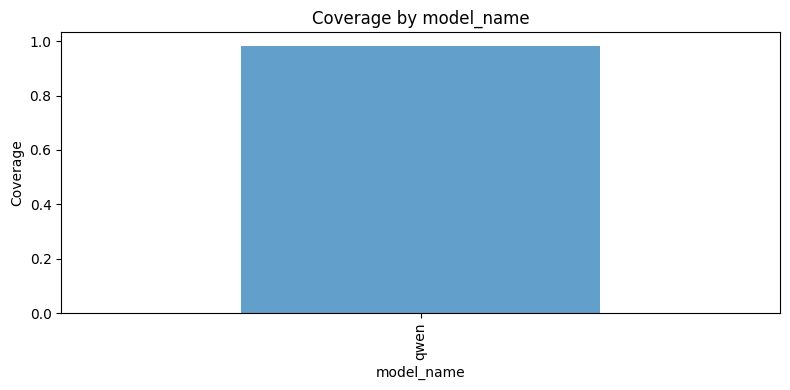

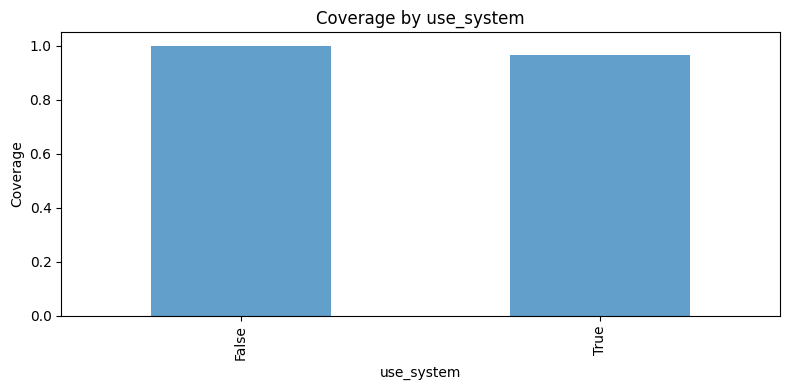

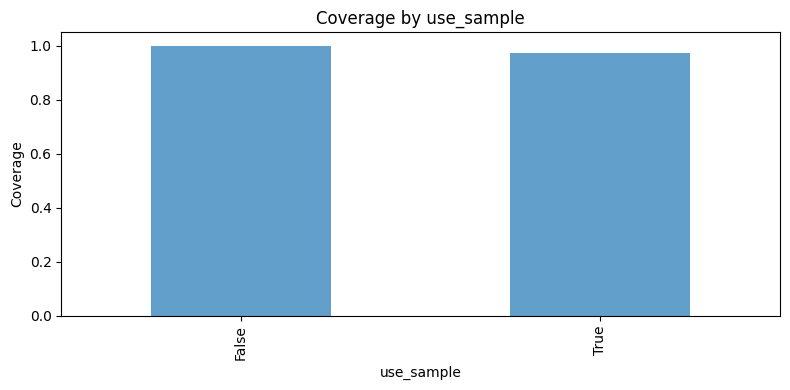

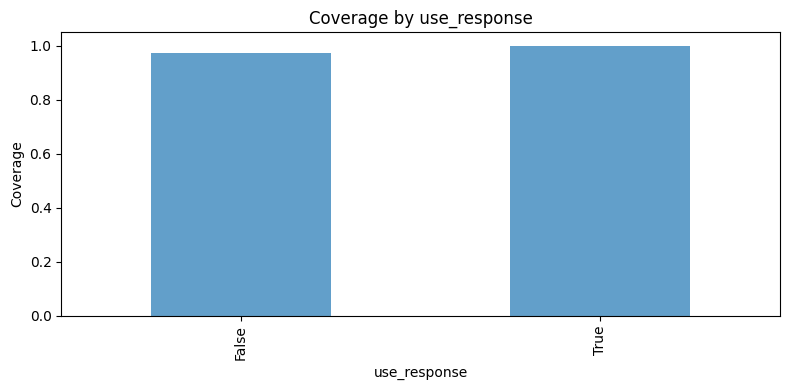

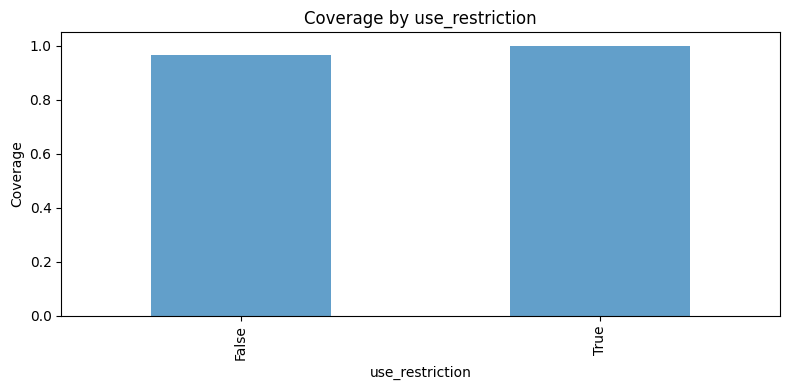

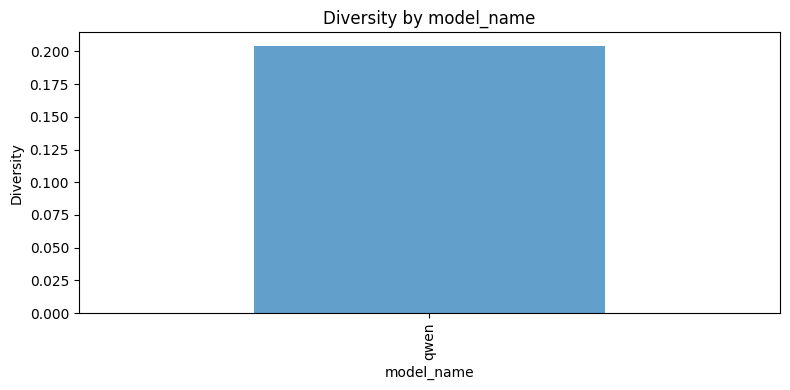

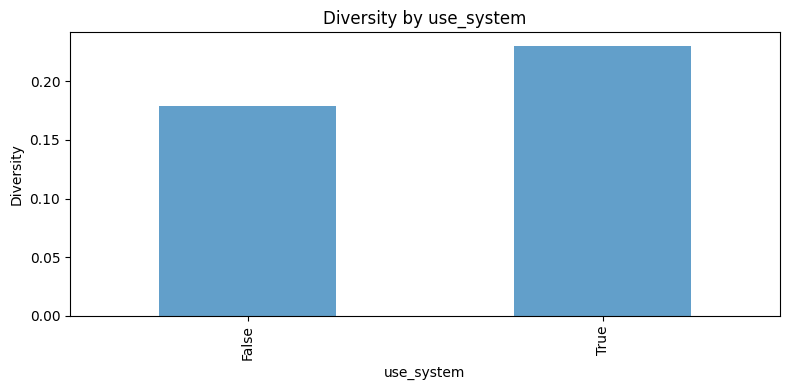

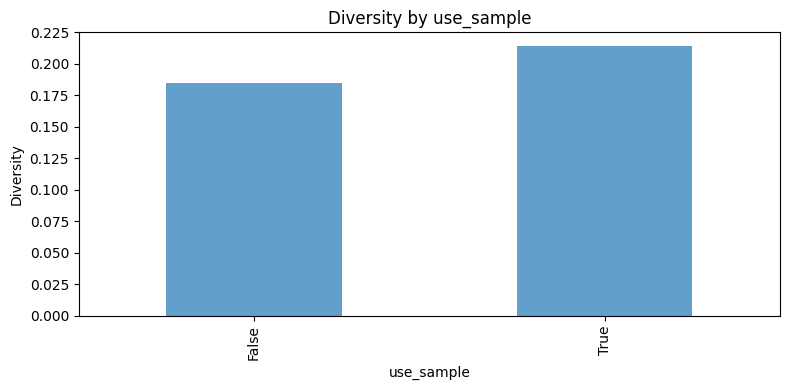

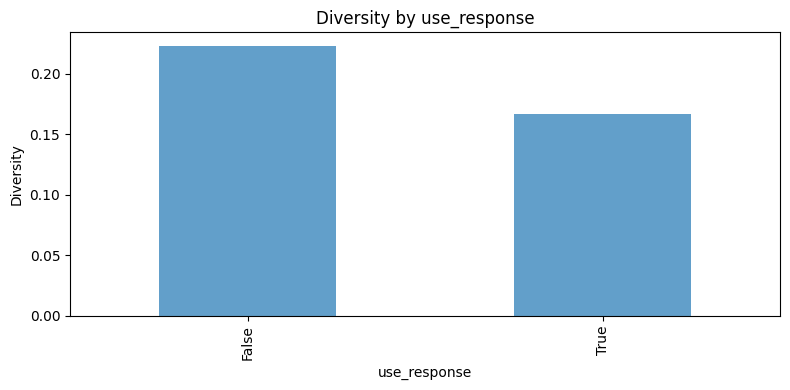

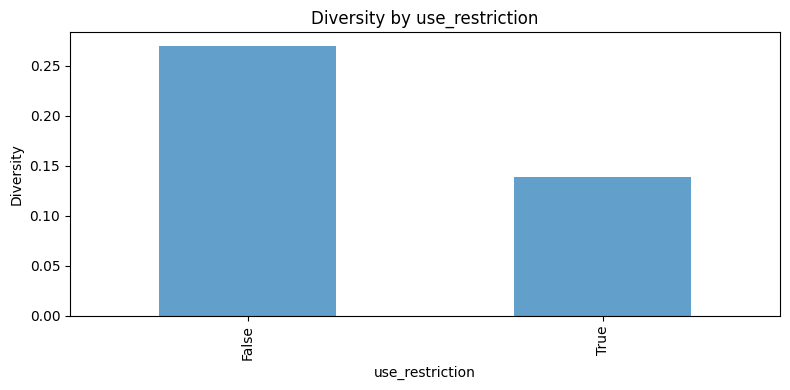

In [ ]:
import pandas as pd

import matplotlib.pyplot as plt

# Convert results to DataFrame and extract components
df_results = pd.DataFrame(total_results)
components = [extract_components(f['file']) for f in total_results]
components_df = pd.DataFrame(components)
df_results = pd.concat([df_results, components_df], axis=1)

# Define columns to plot against
group_cols = ['model_name', 'use_system', 'use_sample', 'use_response', 'use_restriction']

# Plot coverage
for metric in ['coverage', 'diversity']:
    for col in group_cols:
        plt.figure(figsize=(8, 4))
        means = df_results.groupby(col)[metric].mean()
        means.plot(kind='bar', alpha=0.7)
        plt.title(f'{metric.capitalize()} by {col}')
        plt.ylabel(metric.capitalize())
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()

In [ ]:
import matplotlib.pyplot as plt

# Collect all tags from the union of 'tags' in results
all_tags = []
for r in results:
    all_tags.extend(r['tags'])

# Plot histogram of tag frequencies
plt.figure(figsize=(10, 5))
plt.hist(all_tags, bins=len(set(all_tags)), rwidth=0.8)
plt.title('Histogram of Tag Frequencies (Union of All Results)')
plt.xlabel('Tag')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()